# MA crossover backtest

Runs the event-driven `backtest_engine` on the MT5 USDJPY data and shows portfolio tracking and the equity curve. Change the settings in the next cell, then **Run All**.

In [1]:
TIMEFRAME = "5min"   # "1min", "5min", "15min", "1h", "4h" (bars aligned to the 17:00 New York day)
FAST, SLOW = 20, 50  # SMA lengths, in bars
CASH = 10_000        # starting balance, USD
LONG_ONLY = False

# Orders (distances in pips; None = off)
ENTRY = "market"     # "market" (next open), "limit" (better price), "stop" (breakout)
ENTRY_OFFSET = 0     # limit/stop distance from the signal bar's close
EXPIRY_BARS = None   # cancel an unfilled limit/stop entry after this many bars
STOP_LOSS = None     # e.g. 20
TAKE_PROFIT = None   # e.g. 40
TRAILING_STOP = None # e.g. 15

# Position sizing
SIZING = "fixed"     # "fixed", "risk" (needs STOP_LOSS or TRAILING_STOP), "equity"
UNITS = 10_000       # fixed: units per trade (10,000 = 0.1 lot)
RISK_PCT = 1.0       # risk: % of equity lost if the stop is hit
EQUITY_PCT = 100     # equity: notional as % of equity
MAX_LEVERAGE = 30

# Slippage, points per fill (always against you)
SLIPPAGE = 0

In [2]:
%matplotlib inline
from functools import partial

import pandas as pd
from backtest_engine import MovingAverageCrossover, point_size
from backtest_engine.broker import FixedSlippage
from backtest_engine.data_loader import DEFAULT_FILE, MT5_SERVER_TZ, load_ohlcv, resample_ohlcv
from backtest_engine.optimize import RunConfig
from backtest_engine.orders import OrderPolicy
from backtest_engine.sizing import PercentEquity, RiskPercent

df = load_ohlcv(DEFAULT_FILE, tz=MT5_SERVER_TZ)
df = df if TIMEFRAME == "1min" else resample_ohlcv(df, TIMEFRAME)
point = point_size(df["close"].median())
sizer = {"fixed": None,
         "risk": RiskPercent(pct=RISK_PCT, max_leverage=MAX_LEVERAGE),
         "equity": PercentEquity(pct=EQUITY_PCT, max_leverage=MAX_LEVERAGE)}[SIZING]
config = RunConfig(
    symbol="USDJPY", point=point, cash=CASH, units=UNITS, sizer=sizer,
    orders=OrderPolicy(entry=ENTRY, entry_offset_pips=ENTRY_OFFSET, expiry_bars=EXPIRY_BARS,
                       stop_loss_pips=STOP_LOSS, take_profit_pips=TAKE_PROFIT, trailing_stop_pips=TRAILING_STOP),
    slippage=FixedSlippage(SLIPPAGE) if SLIPPAGE else None,
    make_strategy=partial(MovingAverageCrossover, long_only=LONG_ONLY),
)
result = config.run(df, {"fast": FAST, "slow": SLOW}, title=f"USDJPY {TIMEFRAME} - SMA {FAST}/{SLOW} crossover")
print(f"{len(df):,} bars, {len(result.trades)} trades")
for k in ("sizing", "orders", "slippage"):
    print(f"{k.capitalize():9} {result.meta[k]}")

20,022 bars, 491 trades
Sizing    fixed 10,000 units (0.1 lot)
Orders    market
Slippage  none


## Metrics

Annualised figures (CAGR, volatility, Sharpe, Sortino, Calmar) extrapolate a few months of data to a year, so read them with care.

In [3]:
from IPython.display import display_html

m = result.metrics()
tables = [
    g.set_index("metric")[["display"]].rename(columns={"display": section}).style.set_table_attributes(
        'style="display:inline-table; margin-right:24px; vertical-align:top"').to_html()
    for section, g in m.groupby("section", sort=False)
]
display_html("".join(tables), raw=True)

,Returns
metric,
Starting balance,"$10,000.00"
Final equity,"$9,594.37"
Net P&L,-$405.63
Return,-4.06%
Annualised return (CAGR),-14.06%
Gross profit,"$2,600.66"
Gross loss,"-$3,006.28"
Spread paid,$136.10
Slippage paid,$0.00


## Long vs short

In [4]:
money = "${:,.2f}"
result.by_side().style.format({
    "trades": "{:,.0f}", "win_rate_pct": "{:.1f}%", "net_pnl": money, "pips": "{:+,.1f}",
    "profit_factor": "{:.2f}", "avg_trade": money, "spread_paid": money,
})

,trades,win_rate_pct,net_pnl,pips,profit_factor,avg_trade,spread_paid,slippage_paid
Long,245,40.0%,$-70.91,-112.1,0.95,$-0.29,$67.98,0.000000
Short,246,27.6%,$-334.72,-543.3,0.79,$-1.36,$68.12,0.000000
All,491,33.8%,$-405.63,-655.4,0.87,$-0.83,$136.10,0.000000


## Equity curve

Equity is marked to market every bar; balance only moves when a trade closes.

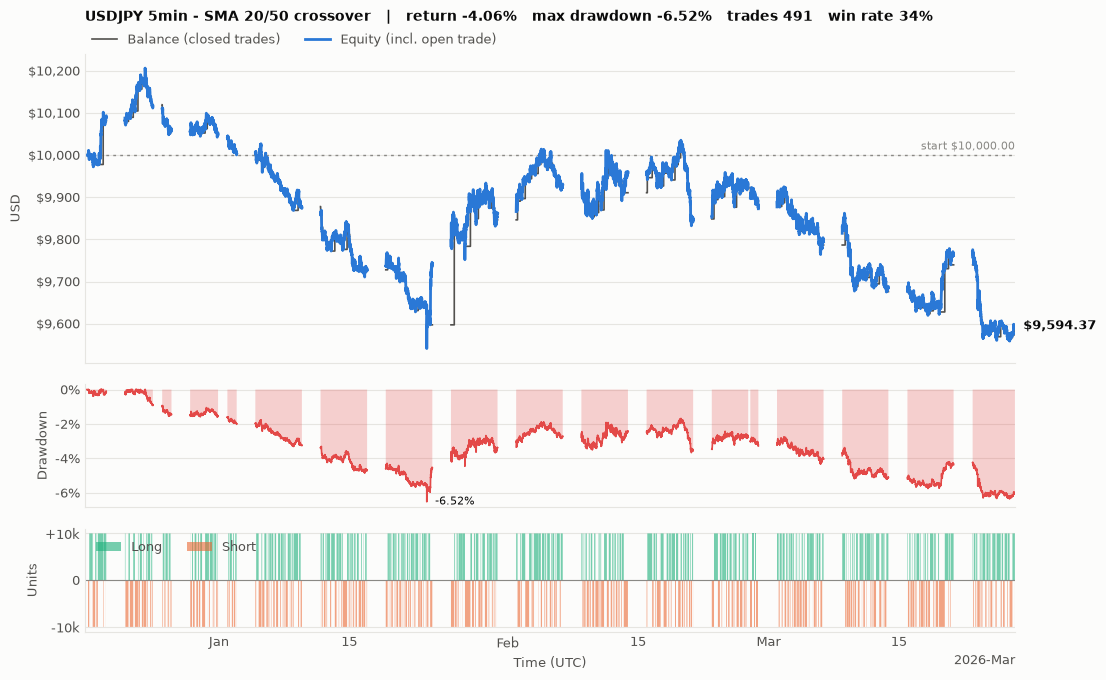

In [5]:
result.plot_equity()

## Portfolio by day

The account at each 17:00 New York close. Drawdown is the worst point reached that day.

In [6]:
result.daily().style.format({
    "close": "{:.3f}", "position": "{:+,.0f}", "balance": money, "open_pnl": money,
    "equity": money, "day_pnl": money, "drawdown_pct": "{:.2f}%",
})

,close,position,balance,open_pnl,equity,day_pnl,trades_closed,drawdown_pct
trading_day,,,,,,,,
2025-12-17,155.686,+0,"$10,000.00",$0.00,"$10,000.00",$0.00,0,0.00%
2025-12-18,155.550,"-10,000","$9,983.29",$1.12,"$9,984.41",$-15.59,8,-0.39%
2025-12-19,157.704,"+10,000","$10,079.96",$9.74,"$10,089.70",$105.29,5,-0.35%
2025-12-22,157.032,"+10,000","$10,112.92",$1.03,"$10,113.95",$24.25,4,-0.30%
2025-12-23,156.239,"+10,000","$10,175.81",$-2.05,"$10,173.76",$59.81,6,-0.29%
2025-12-24,155.886,"-10,000","$10,119.54",$-3.23,"$10,116.30",$-57.46,7,-0.93%
2025-12-26,156.525,"-10,000","$10,058.84",$-0.14,"$10,058.69",$-57.61,12,-1.55%
2025-12-29,156.031,"-10,000","$10,054.88",$-0.33,"$10,054.55",$-4.14,8,-1.55%
2025-12-30,156.419,"+10,000","$10,085.58",$3.90,"$10,089.48",$34.93,7,-1.59%


## Portfolio bar by bar (last 20)

In [7]:
result.portfolio_history().tail(20).style.format({
    "close": "{:.3f}", "position": "{:+,.0f}", "avg_price": "{:.3f}", "balance": money,
    "open_pnl": money, "equity": money, "drawdown_pct": "{:.2f}%",
}, na_rep="-")

,close,position,avg_price,balance,open_pnl,equity,drawdown_pct
time,,,,,,,
2026-03-27 09:20:00+00:00,159.812,"+10,000",159.570,"$9,573.58",$15.14,"$9,588.72",-6.05%
2026-03-27 09:25:00+00:00,159.829,"+10,000",159.570,"$9,573.58",$16.20,"$9,589.78",-6.04%
2026-03-27 09:30:00+00:00,159.831,"+10,000",159.570,"$9,573.58",$16.33,"$9,589.91",-6.04%
2026-03-27 09:35:00+00:00,159.815,"+10,000",159.570,"$9,573.58",$15.33,"$9,588.91",-6.05%
2026-03-27 09:40:00+00:00,159.839,"+10,000",159.570,"$9,573.58",$16.83,"$9,590.41",-6.03%
2026-03-27 09:45:00+00:00,159.837,"+10,000",159.570,"$9,573.58",$16.70,"$9,590.28",-6.04%
2026-03-27 09:50:00+00:00,159.856,"+10,000",159.570,"$9,573.58",$17.89,"$9,591.47",-6.02%
2026-03-27 09:55:00+00:00,159.868,"+10,000",159.570,"$9,573.58",$18.64,"$9,592.22",-6.02%
2026-03-27 10:00:00+00:00,159.843,"+10,000",159.570,"$9,573.58",$17.08,"$9,590.66",-6.03%


## Trade log

Every trade. MAE / MFE are the worst / best open P&L (pips) while the trade was held; *return* is P&L as a % of the balance before the trade. The same log is saved as `backtest_results/*_trade_log.csv`.

In [8]:
from backtest_engine.metrics import format_duration

log = result.trade_log()
log.style.format({
    "entry_time": "{:%Y-%m-%d %H:%M}", "exit_time": "{:%Y-%m-%d %H:%M}", "duration": format_duration,
    "units": "{:,.0f}", "entry_price": "{:.3f}", "exit_price": "{:.3f}", "pips": "{:+.1f}",
    "pnl": money, "return_pct": "{:+.3f}%", "spread_cost": money, "mae_pips": "{:.1f}",
    "mfe_pips": "{:+.1f}", "balance": money, "cum_pnl": money,
}).map(lambda v: "color: #1a7f37" if v > 0 else "color: #c62828" if v < 0 else "", subset=["pips", "pnl"])

,side,entry_time,exit_time,duration,bars_held,units,entry_price,exit_price,pips,pnl,return_pct,spread_cost,slippage_cost,mae_pips,mfe_pips,balance,cum_pnl,exit_reason
trade,,,,,,,,,,,,,,,,,,
1,short,2025-12-17 22:55,2025-12-18 02:05,3h 10m,38,"10,000",155.605,155.728,-12.3,$-7.90,-0.079%,$0.26,0.000000,-18.2,+17.6,"$9,992.10",$-7.90,signal
2,long,2025-12-18 02:05,2025-12-18 05:45,3h 40m,44,"10,000",155.728,155.828,+10.0,$6.42,+0.064%,$0.26,0.000000,-6.6,+10.9,"$9,998.52",$-1.48,signal
3,short,2025-12-18 05:45,2025-12-18 05:50,5m,1,"10,000",155.828,155.863,-3.5,$-2.26,-0.023%,$0.21,0.000000,-3.7,+0.1,"$9,996.26",$-3.74,signal
4,long,2025-12-18 05:50,2025-12-18 09:20,3h 30m,42,"10,000",155.863,155.853,-1.0,$-0.65,-0.007%,$0.21,0.000000,-9.5,+8.9,"$9,995.61",$-4.39,signal
5,short,2025-12-18 09:20,2025-12-18 10:10,50m,10,"10,000",155.853,155.947,-9.4,$-6.03,-0.060%,$0.19,0.000000,-10.2,+0.7,"$9,989.58",$-10.42,signal
6,long,2025-12-18 10:10,2025-12-18 11:50,1h 40m,20,"10,000",155.947,155.762,-18.5,$-11.88,-0.119%,$0.19,0.000000,-18.5,+2.6,"$9,977.70",$-22.30,signal
7,short,2025-12-18 11:50,2025-12-18 17:25,5h 35m,67,"10,000",155.762,155.630,+13.2,$8.48,+0.085%,$0.19,0.000000,-10.6,+47.6,"$9,986.18",$-13.82,signal
8,long,2025-12-18 17:25,2025-12-18 20:25,3h 00m,36,"10,000",155.630,155.585,-4.5,$-2.89,-0.029%,$0.19,0.000000,-13.3,+7.6,"$9,983.29",$-16.71,signal
9,short,2025-12-18 20:25,2025-12-19 00:10,3h 45m,45,"10,000",155.585,155.672,-8.7,$-5.61,-0.056%,$0.35,0.000000,-8.7,+10.2,"$9,977.68",$-22.32,signal
